## 02 · Clean data

This notebook turns the cleaned source files from notebook `01_extract_data` into one dataset that will used afterwards for modelling, and gives a descriptive look at the data.

**Input:** the five CSV files in `data/processed/` (World Bank and IMF prices, GSCPI, industrial production, US dollar index).

**Steps:**

1. **Merge** all sources into one monthly table.
2. **Build the metals index** from copper, aluminium, nickel and tin, using World Bank weights (main specification), additionally equal and USGS weights for robustness checks. The index is built from weighted monthly log price changes, so that metals with high price levels do not dominate the data sample.
3. **Create the target:** the log price change over the next 3 months, for the index and for each metal individually (including cobalt and lithium).
4. **Create the predictors:** supply chain pressure (GSCPI), world demand (12-month growth of industrial production), oil prices and the US dollar (3-month changes), and past price changes. All predictors are lagged by one month, in that manner the models solely use information available at the time of the forecast.
5. **Define the sample** as the months in which all core variables are available.
6. **Describe the data:** summary statistics, time series, the relationship between supply chain pressure and future price changes, the distribution of the target, and correlations.

**Output:** `data/processed/analysis_dataset.csv` (used by `03_model`) and three figures in `figures/`.

*Code written with help of Claude (Anthropic), asked to guide on how to produce a clean code that merges the processed data, builds the metals index and model variables, and describes the data.*

In [1]:
### Setup (load packages and set the necessary folders)

from pathlib import Path
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIGURES = Path("../figures")
FIGURES.mkdir(exist_ok=True)

## Build the data

In [2]:
### Merge all sources 

# read the files
files = ["prices_worldbank.csv", "prices_imf.csv", "gscpi.csv", "industrial_production.csv", "usd.csv"]

data = pd.read_csv(PROCESSED / files[0], parse_dates=["date"])
for file in files[1:]:
    data = data.merge(pd.read_csv(PROCESSED / file, parse_dates=["date"]), on="date", how="outer")

data = data.sort_values("date").set_index("date")
data.loc["2000":].head()

,copper,aluminium,nickel,tin,zinc,lead,brent,naturalgas_index,cobalt,lithium,copper_imf,aluminium_imf,nickel_imf,tin_imf,gscpi,ind_production_world,ind_production_world_importweighted,ind_production_china,us_dollar_neer
date,,,,,,,,,,,,,,,,,,,
2000-01-01,1844.0,1680.0,8310.0,5928.0,1179.0,472.0,25.4,48.2,14437.500000,NaN,1843.850000,1679.850000,8315.250000,5926.250000,-0.604247,60.091737,71.839505,10.830004,91.27
2000-02-01,1801.0,1670.0,9653.0,5642.0,1095.0,452.0,27.7,51.5,14093.750000,NaN,1807.025000,1679.425000,9583.750000,5669.000000,-0.418431,60.656063,72.796745,10.918775,92.49
2000-03-01,1739.0,1577.0,10280.0,5458.0,1116.0,441.0,27.5,53.6,15225.000000,NaN,1739.800000,1579.640000,10255.400000,5463.800000,-0.256743,60.999029,73.377241,10.936529,92.45
2000-04-01,1679.0,1457.0,9728.0,5384.0,1128.0,421.0,22.5,57.4,16218.750000,NaN,1681.907500,1458.745000,9746.500000,5398.050000,0.141659,61.452294,73.572141,11.043054,92.94
2000-05-01,1786.0,1467.0,10130.0,5451.0,1157.0,412.0,27.3,63.4,16543.478261,NaN,1785.097826,1468.065217,10122.913043,5437.956522,0.331939,61.939215,74.158495,11.167332,95.17


In [3]:
### Metal basket index 
### Fixed-weight Laspeyres index, following the World Bank Commodity Price Index: each metal's price is expressed relative to its 2010 average (2010 = 100), and the relatives are combined with the World Bank's metal weights, rescaled to the four metals. Equal and USGS production-based weights are constructed for robustness checks.

METALS = ["copper", "aluminium", "nickel", "tin"]

WEIGHTS = {
    "worldbank": {"copper": 0.511, "aluminium": 0.354, "nickel": 0.107, "tin": 0.028},
    "equal_weights":     {"copper": 0.25,  "aluminium": 0.25,  "nickel": 0.25,  "tin": 0.25},
    "usgs_weights":      {"copper": 0.460, "aluminium": 0.385, "nickel": 0.136, "tin": 0.019},
}

# price relatives: each price divided by its 2010 average, so that 2010 = 100
# (the World Bank's indices use 2010 = 100; see the "Monthly Indices" sheet)
base_prices = data.loc["2010", METALS].mean()
relatives = 100 * data[METALS] / base_prices

# Laspeyres index: weighted average of the price relatives
for name, weights in WEIGHTS.items():
    data[f"index_{name}"] = sum(weights[metal] * relatives[metal] for metal in METALS)

data.loc["2010", ["index_worldbank", "index_equal_weights", "index_usgs_weights"]].mean().round(1)

index_worldbank        100.0
index_equal_weights    100.0
index_usgs_weights     100.0
dtype: float64

In [4]:
### Proof of adding a momentum to the model: The averaging effect
### The World Bank reports monthly averages of daily prices. Averaging prices over time can mechanically induce positive autocorrelation in consecutive monthly price changes, even when the underlying prices follow a random walk with no genuine momentum (Working, 1960). The simulation below demonstrates this effect, while the second part analyzes whether similar autocorrelation is present in the data.

# 1) simulation: a random walk with no momentum, observed as monthly averages
random_number = np.random.default_rng(seed=0)
daily_price = np.cumsum(random_number.normal(size=21 * 10000))          # 10,000 months of 21 trading days
monthly_average = daily_price.reshape(10000, 21).mean(axis=1)
monthly_last_day = daily_price.reshape(10000, 21)[:, -1]

print("simulated random walk, autocorrelation of monthly changes:")
print(f"  end-of-month prices: {pd.Series(monthly_last_day).diff().autocorr():.2f}")
print(f"  monthly averages:    {pd.Series(monthly_average).diff().autocorr():.2f}")

# 2) the same statistic in our data (monthly averages)
monthly_change = np.log(data.loc["2001":"2026-08", ["index_worldbank"] + METALS]).diff()
print("\nour data, autocorrelation of monthly changes:")
print(monthly_change.apply(lambda s: s.autocorr()).round(2).to_string())

simulated random walk, autocorrelation of monthly changes:
  end-of-month prices: -0.00
  monthly averages:    0.26

our data, autocorrelation of monthly changes:
index_worldbank    0.36
copper             0.40
aluminium          0.28
nickel             0.31
tin                0.35


In [5]:
### Targets 
### For the index and each metal: the log price change over the next upcoming 3 months (the target), and over the previous 3 months (momentum, used as a predictor).

# forecast horizon in months
HORIZON = 3                                   

TARGETS = ["index_worldbank", "index_equal_weights", "index_usgs_weights",
           "copper", "aluminium", "nickel", "tin", "zinc", "lead", "cobalt", "lithium"]

for series in TARGETS:
    log_price = np.log(data[series])
    data[f"{series}_next_{HORIZON}m"] = log_price.shift(-HORIZON) - log_price      # change over the next 3 months
    data[f"{series}_past_{HORIZON}m"] = log_price - log_price.shift(HORIZON)    # change over the last 3 months

In [6]:
### Predictors 
### All predictors are lagged by one month, so the models only use information available at the time of the forecast. Demand is measured as 12-month growth; oil, gas and the dollar as 3-month changes. The GSCPI is used as a level, since it is already a standardised index.
### By lagging it secures that all predictors are known at the same moment in time.

# supply chain pressure (a level: 0 = normal pressure)
data["gscpi_lag"] = data["gscpi"].shift(1)

# demand: 12-month growth of industrial production
data["demand_world_12m_lag"]         = np.log(data["ind_production_world"]).diff(12).shift(1)
data["demand_world_importw_12m_lag"] = np.log(data["ind_production_world_importweighted"]).diff(12).shift(1)
data["demand_china_12m_lag"]   = np.log(data["ind_production_china"]).diff(12).shift(1)
data["demand_world_3m_lag"]      = np.log(data["ind_production_world"]).diff(3).shift(1)

# energy and the dollar: 3-month changes
data["oil_3m_lag"] = np.log(data["brent"]).diff(3).shift(1)
data["gas_3m_lag"] = np.log(data["naturalgas_index"]).diff(3).shift(1)
data["usd_3m_lag"] = np.log(data["us_dollar_neer"]).diff(3).shift(1) 

In [7]:
### Sample 
### The sample covers the months in which all core variables are available.

MAIN_TARGET = "index_worldbank_next_3m"
MAIN_PREDICTORS = ["index_worldbank_past_3m", "gscpi_lag", "demand_world_12m_lag", "oil_3m_lag", "usd_3m_lag"]
CORE = [MAIN_TARGET] + MAIN_PREDICTORS

available_months = data.dropna(subset=CORE).index
analysis = data.loc[available_months.min():available_months.max()]

missing = analysis[CORE].isna().sum().sum()
assert missing == 0, f"{missing} missing values inside the sample"

print(f"sample: {analysis.index.min():%Y-%m} to {analysis.index.max():%Y-%m}, {len(analysis)} months")

sample: 2001-02 to 2026-05, 304 months


correlation of levels:            0.999
correlation of 3-month changes:  0.998


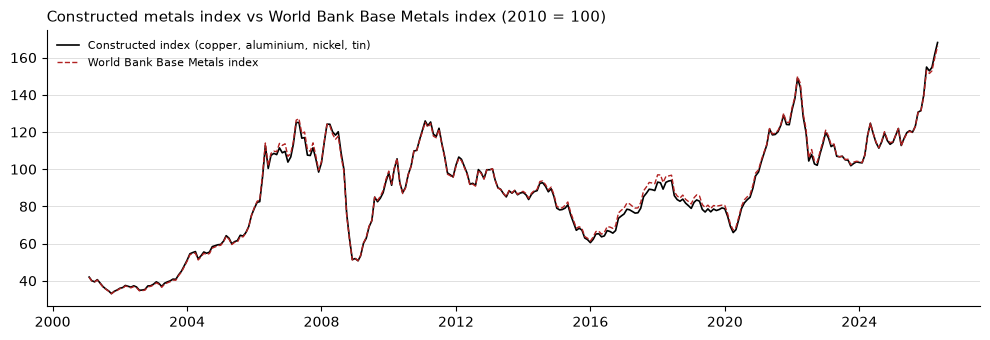

In [8]:
### Index check against the World Bank Metal Index

# official World Bank Base Metals index (sheet "Monthly Indices", column 15)
base_metals_worldbank = pd.read_excel(
    RAW / "worldbank_pinksheet_monthly.xlsx",
    sheet_name="Monthly Indices",
    skiprows=9,
    header=None,
    usecols=[0, 15],
    names=["date", "base_metals_wb"],
)
base_metals_worldbank["date"] = pd.to_datetime(base_metals_worldbank["date"], format="%YM%m")
base_metals_worldbank = base_metals_worldbank.set_index("date")["base_metals_wb"]

# compare over the analysis sample
comparison = pd.concat([data["index_worldbank"], base_metals_worldbank], axis=1).loc[analysis.index]
level_corr = comparison.corr().iloc[0, 1]
change_corr = np.log(comparison).diff(HORIZON).corr().iloc[0, 1]

print(f"correlation of levels:            {level_corr:.3f}")
print(f"correlation of {HORIZON}-month changes:  {change_corr:.3f}")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(comparison.index, comparison["index_worldbank"], color="black", linewidth=1.2,
        label="Constructed index (copper, aluminium, nickel, tin)")
ax.plot(comparison.index, comparison["base_metals_wb"], color="firebrick", linewidth=1,
        linestyle="--", label="World Bank Base Metals index")
ax.set_title("Constructed metals index vs World Bank Base Metals index (2010 = 100)",
             loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="lightgrey", linewidth=0.5)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "index_check.png", dpi=150)
plt.show()

In [9]:
### Save 
### The model-ready variables are saved to `data/processed/analysis_dataset.csv`, which `03_model` uses.

predictors = [c for c in analysis.columns if c.endswith("_lag")]
targets_and_momentum = [c for c in analysis.columns if c.endswith((f"_next_{HORIZON}m", f"_past_{HORIZON}m"))]

columns = predictors + targets_and_momentum
analysis[columns].to_csv(PROCESSED / "analysis_dataset.csv")
print(f"saved analysis_dataset.csv: {len(analysis)} rows, {len(columns)} columns")

saved analysis_dataset.csv: 304 rows, 30 columns


## Descriptive analysis 

In [10]:
# readable names for the core variables
LABELS = {
    "index_worldbank_next_3m": "Metals index, next 3 months",
    "index_worldbank_past_3m": "Metals index, past 3 months",
    "gscpi_lag": "Supply chain pressure (GSCPI)",
    "demand_world_12m_lag": "Industrial demand",
    "oil_3m_lag": "Oil price",
    "usd_3m_lag": "US dollar",
}

# shorter names for compact tables and the correlation matrix
SHORT_LABELS = {
    "index_worldbank_next_3m": "Metals, next 3m (target)",
    "index_worldbank_past_3m": "Metals, past 3m",
    "gscpi_lag": "GSCPI",
    "demand_world_12m_lag": "Demand",
    "oil_3m_lag": "Oil",
    "usd_3m_lag": "US dollar",
}

# raw series shown in the time series figure
PANELS = {
    "index_worldbank": "Metals index (World Bank weights, 2010 = 100)",
    "gscpi": "Supply chain pressure, GSCPI (standard deviations from average)",
    "ind_production_world": "World industrial production (2021 = 100)",
    "brent": "Brent oil price (USD per barrel)",
    "us_dollar_neer": "US dollar, nominal effective exchange rate (2020 = 100)",
}

# crisis periods shaded in the figures
EPISODES = {
    "Financial\ncrisis": ("2007-12", "2009-06"),
    "Oil\ncrash": ("2014-07", "2016-01"),
    "COVID and\nsupply chain crisis": ("2020-02", "2023-01"),
}
    
# GSCPI threshold for high supply chain pressure (standard deviations)
HIGH_PRESSURE = 1

In [11]:
### Summary statistics 
analysis[CORE].describe().round(3)

,index_worldbank_next_3m,index_worldbank_past_3m,gscpi_lag,demand_world_12m_lag,oil_3m_lag,usd_3m_lag
count,304.000,304.000,304.000,304.000,304.000,304.000
mean,0.014,0.013,0.037,0.023,0.012,0.000
std,0.113,0.113,1.040,0.039,0.194,0.027
min,-0.664,-0.664,-1.591,-0.139,-1.004,-0.068
25%,-0.042,-0.044,-0.594,0.013,-0.071,-0.018
50%,0.020,0.020,-0.196,0.029,0.026,-0.001
75%,0.075,0.075,0.295,0.042,0.122,0.017
max,0.316,0.316,4.431,0.164,0.608,0.115


In [12]:
### Overview of each industrial metal 
### Sample coverage and three-month price changes for each series modelled separately.

metal_targets = {series: f"{series}_next_{HORIZON}m" for series in TARGETS}

metal_summary = pd.DataFrame({
    "first month": {series: analysis[target].first_valid_index().strftime("%Y-%m")
                    for series, target in metal_targets.items()},
    "months": {series: analysis[target].count() for series, target in metal_targets.items()},
    "mean (log × 100)": {series: 100 * analysis[target].mean() for series, target in metal_targets.items()},
    "std (log × 100)": {series: 100 * analysis[target].std() for series, target in metal_targets.items()},
    "largest fall (%)": {series: 100 * np.expm1(analysis[target].min()) for series, target in metal_targets.items()},
    "fall month": {series: analysis[target].idxmin().strftime("%Y-%m") for series, target in metal_targets.items()},
    "largest rise (%)": {series: 100 * np.expm1(analysis[target].max()) for series, target in metal_targets.items()},
    "rise month": {series: analysis[target].idxmax().strftime("%Y-%m") for series, target in metal_targets.items()},
})
metal_summary.round(1)

,first month,months,mean (log × 100),std (log × 100),largest fall (%),fall month,largest rise (%),rise month
index_worldbank,2001-02,304,1.4,11.3,-48.5,2008-09,37.1,2006-02
index_equal_weights,2001-02,304,1.5,11.7,-45.1,2008-09,35.1,2009-03
index_usgs_weights,2001-02,304,1.3,11.2,-47.9,2008-09,35.9,2009-05
copper,2001-02,304,2.1,13.7,-56.1,2008-09,61.5,2006-02
aluminium,2001-02,304,0.7,10.3,-41.0,2008-09,32.5,2009-05
nickel,2001-02,304,1.0,17.5,-47.0,2007-05,69.5,2021-12
tin,2001-02,304,2.3,14.3,-40.9,2022-04,45.2,2022-10
zinc,2001-02,304,1.3,13.5,-36.5,2008-09,60.7,2006-02
lead,2001-02,304,1.3,13.4,-48.4,2008-09,54.1,2007-04
cobalt,2001-02,304,1.4,21.6,-52.0,2008-09,154.7,2002-12


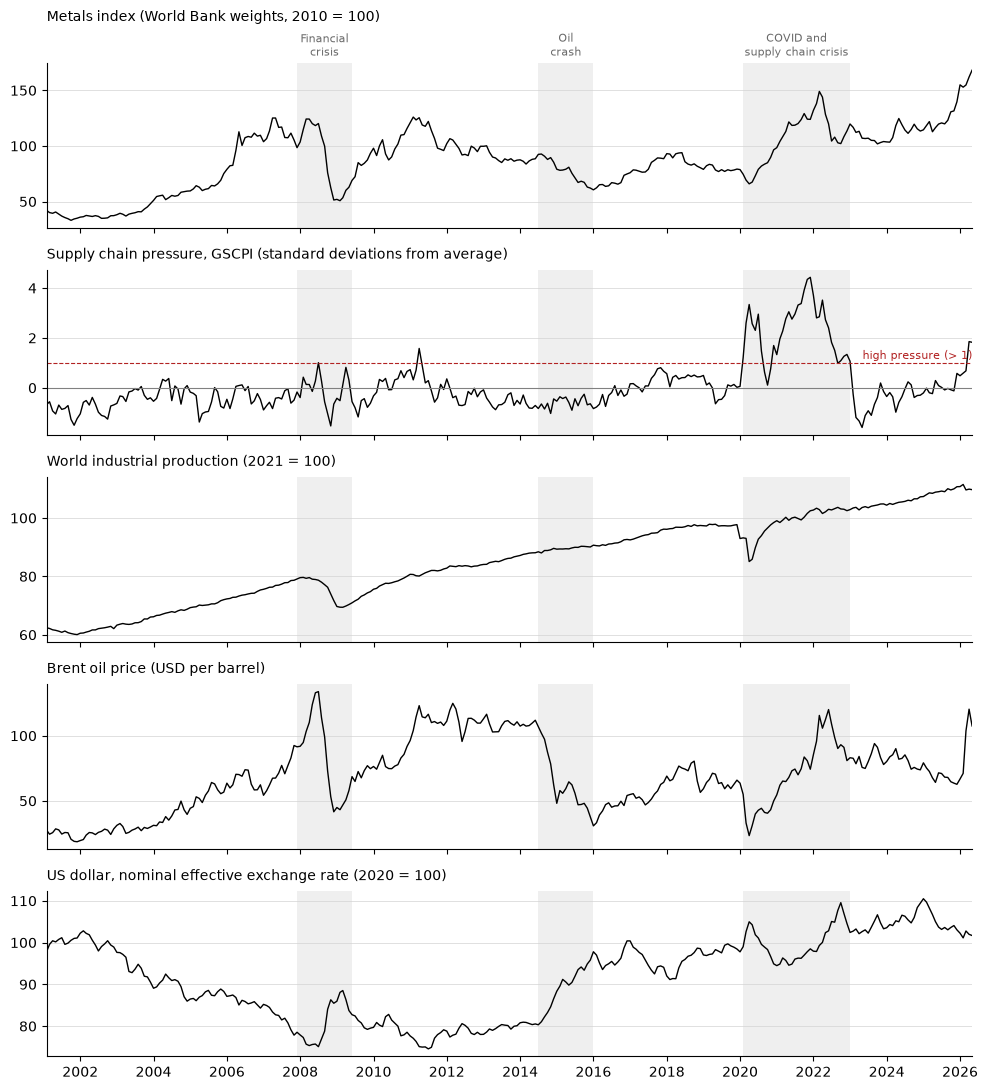

In [13]:
### Time series: evolution of the variables over time 

fig, axes = plt.subplots(len(PANELS), 1, figsize=(10, 11), sharex=True)

# one panel per series, with the crisis periods shaded
for ax, (column, title) in zip(axes, PANELS.items()):
    for start, end in EPISODES.values():
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="grey", alpha=0.12, linewidth=0)
    ax.plot(analysis.index, analysis[column], color="black", linewidth=1)
    ax.set_title(title, loc="left", fontsize=10, pad=8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="lightgrey", linewidth=0.5)

# episode names above the first panel
axes[0].set_title(PANELS["index_worldbank"], loc="left", fontsize=10, pad=30)
for name, (start, end) in EPISODES.items():
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    axes[0].text(start + (end - start) / 2, 1.02, name, transform=axes[0].get_xaxis_transform(),
                 ha="center", va="bottom", fontsize=8, color="dimgrey")

# reference lines on the GSCPI panel
gscpi_ax = axes[list(PANELS).index("gscpi")]
gscpi_ax.axhline(0, color="grey", linewidth=0.8)
gscpi_ax.axhline(1, color="firebrick", linewidth=0.8, linestyle="--")
gscpi_ax.text(analysis.index.max(), 1.05, "high pressure (> 1)", fontsize=8,
              color="firebrick", ha="right", va="bottom")

axes[-1].set_xlim(analysis.index.min(), analysis.index.max())
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fig.tight_layout()
fig.savefig(FIGURES / "time_series.png", dpi=150)
plt.show()

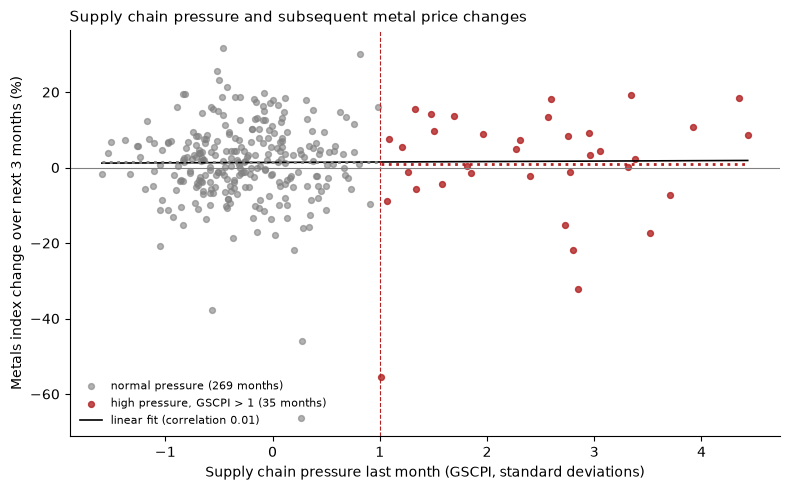

In [14]:
### Scatter plot: relationship between supply chain pressure and future prices changes 

HIGH_PRESSURE = 1   # GSCPI above one standard deviation

gscpi = analysis["gscpi_lag"]
change = 100 * analysis[MAIN_TARGET]   # next 3-month change in %
high = gscpi > HIGH_PRESSURE

fig, ax = plt.subplots(figsize=(8, 5))

# dots: normal months grey, high-pressure months red
ax.scatter(gscpi[~high], change[~high], s=18, color="grey", alpha=0.6,
           label=f"normal pressure ({(~high).sum()} months)")
ax.scatter(gscpi[high], change[high], s=18, color="firebrick", alpha=0.8,
           label=f"high pressure, GSCPI > {HIGH_PRESSURE} ({high.sum()} months)")

# straight-line fit through all months
slope, intercept = np.polyfit(gscpi, change, 1)
x_line = np.linspace(gscpi.min(), gscpi.max(), 100)
ax.plot(x_line, intercept + slope * x_line, color="black", linewidth=1.2,
        label=f"linear fit (correlation {gscpi.corr(change):.2f})")

# average change in each regime
for regime, color in [(~high, "grey"), (high, "firebrick")]:
    ax.hlines(change[regime].mean(), gscpi[regime].min(), gscpi[regime].max(),
              color=color, linewidth=2, linestyle=":")

# reference lines
ax.axvline(HIGH_PRESSURE, color="firebrick", linewidth=0.8, linestyle="--")
ax.axhline(0, color="grey", linewidth=0.8)

ax.set_xlabel("Supply chain pressure last month (GSCPI, standard deviations)")
ax.set_ylabel("Metals index change over next 3 months (%)")
ax.set_title("Supply chain pressure and subsequent metal price changes", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower left")

fig.tight_layout()
fig.savefig(FIGURES / "scatter_gscpi.png", dpi=150)
plt.show()

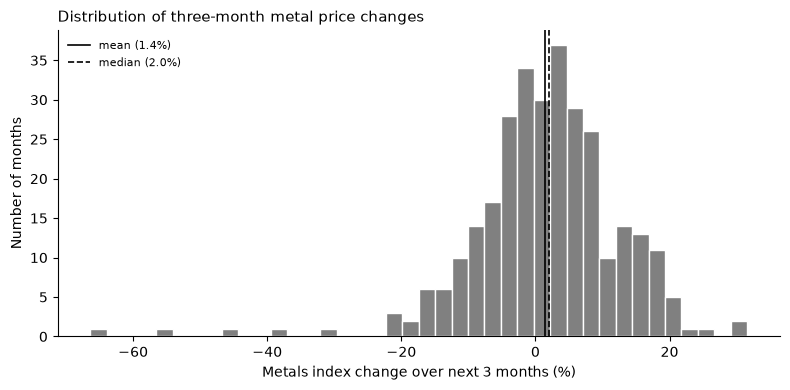

standard deviation: 11.3%
skewness:           -1.42
excess kurtosis:    6.86

largest falls (%):
date
2008-09-01   -66.4
2008-08-01   -55.5
2008-07-01   -45.9
2008-10-01   -37.9
2022-04-01   -32.1

largest rises (%):
date
2006-02-01    31.6
2009-05-01    30.2
2009-03-01    25.7
2007-12-01    23.2
2009-02-01    21.4


In [15]:
### Distribution of the target
### Three-month changes in the metals index. Heavy tails matter for the evaluation: a few large errors can dominate the mean squared error.

metals_change_pct = 100 * analysis[MAIN_TARGET]   # next 3-month change in %

fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(metals_change_pct, bins=40, color="grey", edgecolor="white")
ax.axvline(metals_change_pct.mean(), color="black", linewidth=1.2,
           label=f"mean ({metals_change_pct.mean():.1f}%)")
ax.axvline(metals_change_pct.median(), color="black", linewidth=1.2, linestyle="--",
           label=f"median ({metals_change_pct.median():.1f}%)")

ax.set_xlabel("Metals index change over next 3 months (%)")
ax.set_ylabel("Number of months")
ax.set_title("Distribution of three-month metal price changes", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper left")

fig.tight_layout()
fig.savefig(FIGURES / "target_histogram.png", dpi=150)
plt.show()

print(f"standard deviation: {change.std():.1f}%")
print(f"skewness:           {change.skew():.2f}")
print(f"excess kurtosis:    {change.kurt():.2f}")
print("\nlargest falls (%):")
print(change.nsmallest(5).round(1).to_string())
print("\nlargest rises (%):")
print(change.nlargest(5).round(1).to_string())

In [16]:
### High pressure months: normal vs. high supply chain pressure 
### Comparison of three-month metal price changes after months with normal pressure and after months with high pressure (GSCPI > 1).

metals_change_pct = 100 * analysis[MAIN_TARGET]   # next 3-month change in %
high_pressure= analysis["gscpi_lag"] > HIGH_PRESSURE
pressure_level = high_pressure.map({True: "high pressure", False: "normal"}).rename("pressure level")

metals_change_pct.groupby(pressure_level).agg(["count", "mean", "median", "std", "min", "max"]).round(1)

,count,mean,median,std,min,max
pressure level,,,,,,
high pressure,35,0.9,4.3,15.2,-55.5,19.4
normal,269,1.4,1.8,10.7,-66.4,31.6


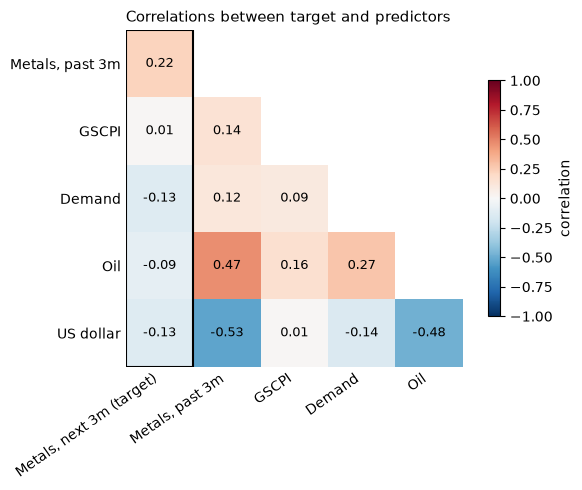

,index_worldbank_next_3m,index_worldbank_past_3m,gscpi_lag,demand_world_12m_lag,oil_3m_lag,usd_3m_lag
index_worldbank_next_3m,1.00,0.22,0.01,-0.13,-0.09,-0.13
index_worldbank_past_3m,0.22,1.00,0.14,0.12,0.47,-0.53
gscpi_lag,0.01,0.14,1.00,0.09,0.16,0.01
demand_world_12m_lag,-0.13,0.12,0.09,1.00,0.27,-0.14
oil_3m_lag,-0.09,0.47,0.16,0.27,1.00,-0.48
usd_3m_lag,-0.13,-0.53,0.01,-0.14,-0.48,1.00


In [17]:
### Correlations
### Analysis of pairwise correlations between the target and the predictors. 
### If two predictors moved closely together, the model could not tell which of them drives the effect. Low correlations between predictors mean each one's contribution can be measured separately.

correlations = analysis[CORE].corr()
names = [SHORT_LABELS[column] for column in CORE]

# hide the diagonal and the upper half (repetition of the lower half)
upper_half = np.triu(np.ones(correlations.shape, dtype=bool))
lower_half = correlations.mask(upper_half)

fig, ax = plt.subplots(figsize=(6.5, 5))
image = ax.imshow(lower_half, cmap="RdBu_r", vmin=-1, vmax=1)

# write the correlation in each shown cell
for row in range(len(CORE)):
    for col in range(len(CORE)):
        if upper_half[row, col]:
            continue
        value = correlations.iloc[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(value) > 0.6 else "black")

# frame the target column: correlations of each predictor with the target
ax.add_patch(plt.Rectangle((-0.5, 0.5), 1, len(CORE) - 1, fill=False,
                           edgecolor="black", linewidth=1.5))

# drop the empty first row and last column
ax.set_xlim(-0.5, len(CORE) - 1.5)
ax.set_ylim(len(CORE) - 0.5, 0.5)

ax.set_xticks(range(len(CORE) - 1))
ax.set_xticklabels(names[:-1], rotation=35, ha="right")
ax.set_yticks(range(1, len(CORE)))
ax.set_yticklabels(names[1:])
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.set_title("Correlations between target and predictors", loc="left", fontsize=11)
fig.colorbar(image, ax=ax, shrink=0.7, label="correlation")

fig.tight_layout()
fig.savefig(FIGURES / "correlations.png", dpi=150)
plt.show()

correlations.round(2)

In [18]:
### Extreme values (outliers)
### Months in which a variable is more than three standard deviations from its mean. These are checked against well-known events and kept in the data. In a further step, their influence will be tested in the robustness checks.

# 1. flag values more than 3 standard deviations from their mean
distance_from_mean = (analysis[CORE] - analysis[CORE].mean()).abs()
outliers = distance_from_mean > 3 * analysis[CORE].std()

# 2. count extreme months per variable
print("extreme months per variable (> 3 std):")
print(outliers.sum().to_string())

# 3. count months with at least one extreme value
outlier_months = outliers.any(axis=1)
print(f"\n{outlier_months.sum()} of {len(analysis)} months have at least one extreme value")

# 4. show the actual values, only where they are extreme
outlier_table = analysis.loc[outlier_months, CORE].round(3)
outlier_table = outlier_table.where(outliers[outlier_months], "")

extreme months per variable (> 3 std):
index_worldbank_next_3m     4
index_worldbank_past_3m     4
gscpi_lag                   8
demand_world_12m_lag       11
oil_3m_lag                  8
usd_3m_lag                  2

27 of 304 months have at least one extreme value


In [19]:
for variable in CORE:
    months = outliers.index[outliers[variable]]
    print(f"{variable}: {', '.join(months.strftime('%Y-%m'))}")

index_worldbank_next_3m: 2008-07, 2008-08, 2008-09, 2008-10
index_worldbank_past_3m: 2008-10, 2008-11, 2008-12, 2009-01
gscpi_lag: 2020-05, 2021-09, 2021-10, 2021-11, 2021-12, 2022-01, 2022-02, 2022-05
demand_world_12m_lag: 2009-01, 2009-02, 2009-03, 2009-04, 2009-05, 2009-06, 2009-07, 2020-05, 2020-06, 2021-05, 2021-06
oil_3m_lag: 2008-11, 2008-12, 2009-01, 2015-02, 2020-04, 2020-05, 2020-06, 2020-08
usd_3m_lag: 2008-11, 2008-12


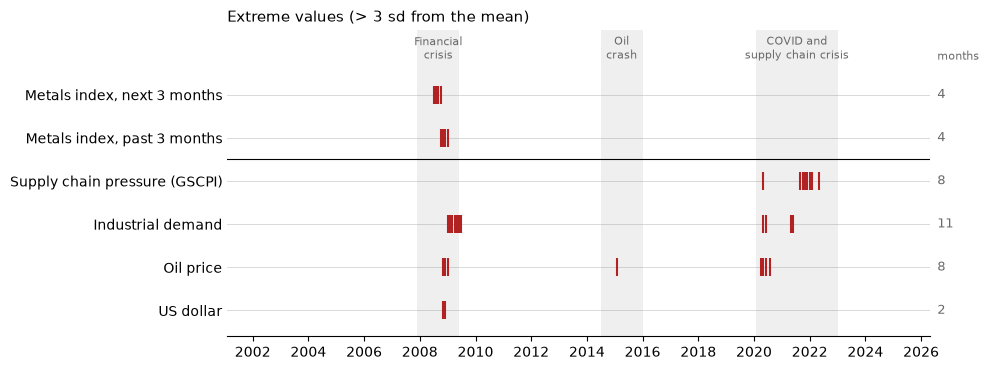

In [20]:
variables = CORE[::-1]   # reverse so the target is on top

fig, ax = plt.subplots(figsize=(10, 3.8))

# shading of the crisis periods and their name
for name, (start, end) in EPISODES.items():
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    ax.axvspan(start, end, color="grey", alpha=0.12, linewidth=0)
    ax.text(start + (end - start) / 2, len(variables) - 0.25, name,
            ha="center", va="bottom", fontsize=8, color="dimgrey")

# one row per variable: guide line, extreme months, count of outlier monthson the right
for row, variable in enumerate(variables):
    months = outliers.index[outliers[variable]]
    ax.axhline(row, color="lightgrey", linewidth=0.6, zorder=0)
    ax.scatter(months, [row] * len(months), marker="|", s=150, linewidths=1.5, color="firebrick")
    ax.text(1.01, row, f"{len(months)}", transform=ax.get_yaxis_transform(),
            va="center", fontsize=9, color="dimgrey")

# addition of a dividing line between the metal variables and the other predictors
ax.axhline(len(variables) - 2.5, color="black", linewidth=0.8)
ax.text(1.01, len(variables) - 0.25, "months", transform=ax.get_yaxis_transform(),
        va="bottom", fontsize=8, color="dimgrey")

ax.set_yticks(range(len(variables)))
ax.set_yticklabels([LABELS[v] for v in variables])
ax.set_ylim(-0.6, len(variables) + 0.5)
ax.set_xlim(analysis.index.min(), analysis.index.max())
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Extreme values (> 3 sd from the mean)", loc="left", fontsize=11)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)

fig.tight_layout()
fig.savefig(FIGURES / "extreme_values_timeline.png", dpi=150)
plt.show()

**Interpretation.** Dates refer to the forecast month; lagged predictors therefore reflect the previous month.

- **2008–09, global financial crisis:** the largest metal price falls (target Jul–Oct 2008, momentum Oct 2008–Jan 2009), the oil collapse and the dollar surge (Nov–Dec 2008), and the fall in industrial demand (Jan–Jul 2009).
- **2015, oil price crash:** extreme oil change in Feb 2015.
- **2020, COVID shock:** collapse in oil prices (Apr–Aug 2020) and industrial demand (May–Jun 2020), and a first spike in supply chain pressure (May 2020).
- **2021, demand rebound:** extreme 12-month demand growth (May–Jun 2021) relative to the low level of 2020.
- **2021–22, supply chain crisis:** extreme GSCPI values (Sep 2021–Feb 2022) and the Shanghai lockdown (May 2022).

All of the outliers in the data (extreme values) correspond to known economic or financial events rather than data errors and are kept in the sample. The extreme metal price movements (2008) and the extreme supply chain pressure (2020–22) do not occur in the same months. Their influence is assessed in the robustness checks.

In [21]:
### Stationarity test
### Augmented Dickey-Fuller tests. The null hypothesis is a unit root (the series drifts without returning to a mean); a p-value below 0.05 rejects it, so the series is stationary.

adf_results = {}
for column in CORE:
    statistic, p_value, lags, *_ = adfuller(analysis[column], autolag="AIC", result_object=False)
    adf_results[SHORT_LABELS[column]] = {
        "ADF statistic": round(statistic, 2),
        "p-value": round(p_value, 3),
        "lags used": lags,
        "stationary (5%)": "yes" if p_value < 0.05 else "no",
    }

pd.DataFrame(adf_results).T

,ADF statistic,p-value,lags used,stationary (5%)
"Metals, next 3m (target)",-3.92,0.002,16,yes
"Metals, past 3m",-3.89,0.002,16,yes
GSCPI,-3.47,0.009,1,yes
Demand,-4.57,0.0,16,yes
Oil,-4.8,0.0,13,yes
US dollar,-3.46,0.009,15,yes


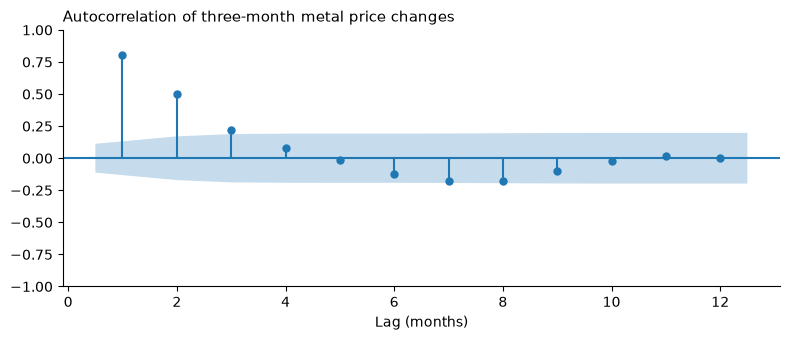

In [22]:
### Autocorrelation of the target
### Each target covers the next three months, so neighbouring targets overlap and are strongly correlated at lags 1 and 2. The observations are therefore not independent, and the regressions use Newey-West standard errors with three lags.

fig, ax = plt.subplots(figsize=(8, 3.5))
plot_acf(analysis[MAIN_TARGET], lags=12, ax=ax, zero=False, title="")
ax.set_title("Autocorrelation of three-month metal price changes", loc="left", fontsize=11)
ax.set_xlabel("Lag (months)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "target_autocorrelation.png", dpi=150)
plt.show()